```markdown
# Chennai Smart Traffic Management using A* Search

## Project Overview
This project implements an intelligent traffic routing system for Chennai, India, using the **A* Search Algorithm**. By integrating real-world geospatial road network data with dynamic traffic observations, the system identifies optimal routes and estimates travel times under varying traffic scenarios: **Normal, Medium, and Heavy**.

---

## Key Steps in the Solution

### 1. Road Network Extraction
* We used the **OSMnx** library to download and construct a drivable road network graph of Chennai from OpenStreetMap (OSM).
* The resulting graph contains **69,376 nodes** and **175,682 edges** representing roads and intersections.

### 2. Traffic Data Integration
* Dynamic traffic speeds and density datasets representing **Normal, Medium, and Heavy** traffic states were matched to the nearest road network nodes using a **Spatial KD-Tree** (`scipy.spatial.cKDTree`).
* Missing speeds and edge costs were dynamically interpolated to compute scenario-specific travel times (in seconds) for every road segment (edge).

### 3. A* Heuristic Search Implementation
* To find the absolute fastest path from **Perambur - Vyasarpadi** to **Tambaram Bypass**, we utilized the A* search algorithm.
* **The Heuristic Function ($h(n)$):** We defined a custom admissible heuristic using **great-circle (straight-line) distance** divided by a maximum legal speed limit (120 km/h expressed as 33.3 m/s):
  $$h(n) = \frac{\text{Great Circle Distance (meters)}}{33.3 \text{ m/s}}$$
* Since straight-line travel time is always less than or equal to actual road-network travel time, this heuristic is strictly **admissible** (never overestimates) and **consistent**, ensuring an optimal path is found efficiently.

---

## Summary of Findings
For the journey from **Perambur - Vyasarpadi** to **Tambaram Bypass**:

| Traffic Condition | Path Nodes | Estimated Time (Minutes) | Recommendation |
| :--- | :---: | :---: | :---: |
| **Normal** | 450 | 21.38 mins | Standard |
| **Medium** | 381 | **18.81 mins** | **Optimal/Recommended** |
| **Heavy** | 376 | 32.23 mins | Heavy Congestion |

* **Optimal Route:** The A* algorithm adapted dynamically to the traffic states, choosing the **Medium Traffic Route** as the most time-efficient path (18.81 minutes).
```

# Chennai Smart Traffic Management Using A* Search
**Mini-Project | Fundamentals of Artificial Intelligence**

**Approach:** Use Chennai's road network and normal, medium, and heavy traffic datasets to estimate travel time and compare routes found by A* search.

## 1. Import Libraries
Load the Python libraries used in this project.

In [3]:
%pip -q install osmnx networkx pandas matplotlib openlocationcode

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:

import osmnx as ox
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import os

print("All libraries imported successfully!")
print("OSMnx version:", ox.__version__)


All libraries imported successfully!
OSMnx version: 2.1.1


## 2. Configure Road Network Download
Set OSMnx options for loading the Chennai road network.

In [5]:


import osmnx as ox

ox.settings.overpass_url = "https://overpass-api.de/api"
ox.settings.timeout = 180
ox.settings.requests_timeout = 200
ox.settings.use_cache = True

print("Overpass URL:", ox.settings.overpass_url)
print("Settings updated successfully!")



Overpass URL: https://overpass-api.de/api
Settings updated successfully!


## 3. Load Chennai Road Network
Download the drivable road graph for Chennai.

In [6]:

try:
    G = ox.graph_from_place(
        "Chennai, Tamil Nadu, India",
        network_type="drive",
        simplify=True
    )

    print("Chennai road network loaded successfully!")
    print("Nodes:", len(G.nodes))
    print("Edges:", len(G.edges))

except Exception as e:
    print("Graph loading failed!")
    print(type(e).__name__)
    print(str(e)[:1000])


Chennai road network loaded successfully!
Nodes: 69376
Edges: 175682


## 4. Save Road Network
Save the graph so it can be reused.

In [7]:

ox.save_graphml(G, "chennai_roads.graphml")

print("Chennai road network saved successfully!")



Chennai road network saved successfully!


## 5. Visualize Road Network
Display the road network used for route planning.

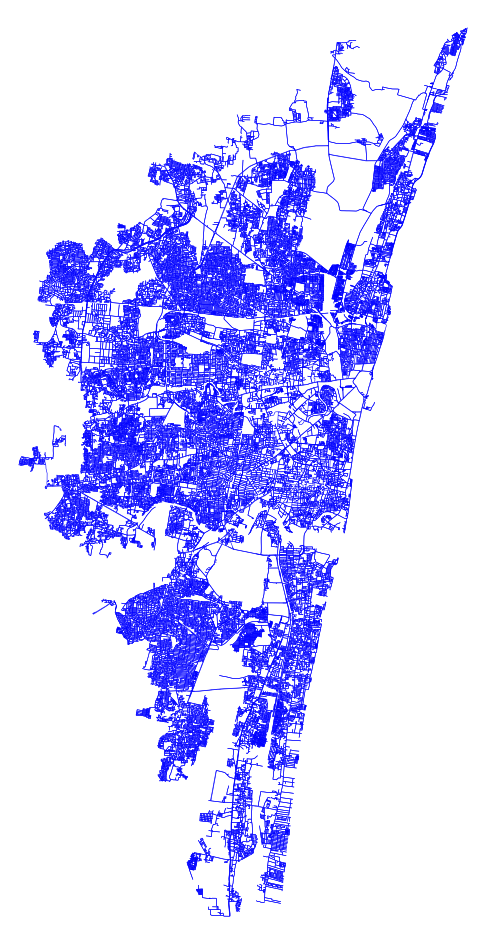

In [8]:

fig, ax = ox.plot_graph(
    G,
    node_size=0,
    edge_linewidth=0.4,
    edge_color="blue",
    bgcolor="white",
    figsize=(12, 12)
)
plt.show()


## 6. Load Traffic Datasets
Load normal, medium, and heavy traffic CSV files.

In [9]:

import pandas as pd

df_normal = pd.read_csv("chennai_traffic_dataset.csv")
df_medium = pd.read_csv("chennai_traffic_MEDIUM.csv")
df_heavy = pd.read_csv("chennai_traffic_HEAVY.csv")

print(df_normal.shape, df_medium.shape, df_heavy.shape)
print(df_normal.columns.tolist())


(5760, 12) (5760, 12) (5760, 12)
['timestamp', 'sensor_id', 'corridor', 'latitude', 'longitude', 'vehicle_count', 'speed', 'traffic_density', 'weather', 'day_type', 'hour_of_day', 'is_peak_hour']


## 7. Inspect Traffic Data
Check sample records and missing values.

In [10]:

print(df_normal[['latitude', 'longitude', 'speed', 'traffic_density']].head())
print("\nMissing values:", df_normal.isnull().sum().sum())


    latitude  longitude   speed  traffic_density
0  12.951046  80.142042  119.14           0.0322
1  12.981112  80.221352  110.30           0.0349
2  13.056982  80.242166  113.04           0.0402
3  13.052728  80.212312  118.02           0.0304
4  12.900799  80.227421  120.00           0.0414

Missing values: 153


## 8. Install Extra Dependency
Install scikit-learn as in the original notebook.

In [11]:

%pip install scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 9. Match Normal Traffic Points to Roads
Find the nearest road node for each normal-traffic location.

In [12]:
import osmnx as ox
# Find the nearest road node for each traffic location
df_normal['nearest_node'] = ox.distance.nearest_nodes(
    G,
    X=df_normal['longitude'],
    Y=df_normal['latitude']
)

print(df_normal[['latitude', 'longitude', 'nearest_node']].head())
print("Traffic points connected:", df_normal['nearest_node'].notna().sum())


    latitude  longitude  nearest_node
0  12.951046  80.142042    6328430470
1  12.981112  80.221352   12244063246
2  13.056982  80.242166   13327970091
3  13.052728  80.212312    6212976333
4  12.900799  80.227421    5458026863
Traffic points connected: 5760


## 10. Match Medium and Heavy Traffic Points
Connect the other traffic datasets to the road network.

In [13]:
# here we r connecting all 3 traffic
for df in [df_medium, df_heavy]:
    df['nearest_node'] = ox.distance.nearest_nodes(
        G,
        X=df['longitude'],
        Y=df['latitude']
    )

print("Medium connected:", df_medium['nearest_node'].notna().sum())
print("Heavy connected:", df_heavy['nearest_node'].notna().sum())


Medium connected: 5760
Heavy connected: 5760


## 11. Inspect Road Edge Information
View attributes for a sample road segment.

In [14]:

# Check road network edge attributes
u, v, k, data = next(iter(G.edges(keys=True, data=True)))

print("Sample road edge:")
print(data)


Sample road edge:
{'osmid': 209562047, 'highway': 'secondary', 'name': 'Langs Garden Road', 'oneway': True, 'reversed': False, 'length': np.float64(12.498709171778236)}


## 12. Summarize Traffic Speeds
Review speed statistics for all three conditions.

In [15]:

print("Normal traffic speed:")
print(df_normal['speed'].describe())

print("\nMedium traffic speed:")
print(df_medium['speed'].describe())

print("\nHeavy traffic speed:")
print(df_heavy['speed'].describe())


Normal traffic speed:
count    5709.000000
mean       78.980948
std        30.714246
min         5.000000
25%        61.920000
50%        81.070000
75%       106.670000
max       120.000000
Name: speed, dtype: float64

Medium traffic speed:
count    5725.000000
mean       84.267116
std        20.937572
min        12.160000
25%        69.790000
50%        83.610000
75%       104.380000
max       120.000000
Name: speed, dtype: float64

Heavy traffic speed:
count    5723.000000
mean       49.925277
std        32.061852
min         5.000000
25%        23.125000
50%        44.940000
75%        78.835000
max       120.000000
Name: speed, dtype: float64


## 13. Estimate Basic Edge Travel Time
Calculate an initial travel-time estimate for road segments.

In [16]:

# Add estimated travel time to each road edge
for u, v, k, data in G.edges(keys=True, data=True):
    length_m = data.get('length', 0)
    speed_kmh = 40  # Temporary default speed

    data['travel_time'] = (length_m / 1000) / (speed_kmh / 3600)

print("Travel time added to road network!")

# Check one road edge
u, v, k, data = next(iter(G.edges(keys=True, data=True)))
print("Road length (m):", data['length'])
print("Travel time (seconds):", round(data['travel_time'], 2))


Travel time added to road network!
Road length (m): 12.498709171778236
Travel time (seconds): 1.12


## 14. Check Data Files and Reload Datasets
Inspect the notebook folder and traffic files.

In [17]:

import pandas as pd
from pathlib import Path

# Current notebook folder
folder = Path.cwd()

print("Notebook folder:", folder)

# Show available CSV files
print("\nCSV files found:")
for file in folder.glob("*.csv"):
    print(file.name)

# Load the three traffic datasets
df_normal = pd.read_csv(folder / "chennai_traffic_dataset.csv")
df_medium = pd.read_csv(folder / "chennai_traffic_MEDIUM.csv")
df_heavy = pd.read_csv(folder / "chennai_traffic_HEAVY.csv")

# Display dataset information
print("\nNormal traffic shape:", df_normal.shape)
print("Medium traffic shape:", df_medium.shape)
print("Heavy traffic shape:", df_heavy.shape)

# Display column names
print("\nNormal traffic columns:")
print(df_normal.columns.tolist())

print("\nMedium traffic columns:")
print(df_medium.columns.tolist())

print("\nHeavy traffic columns:")
print(df_heavy.columns.tolist())


Notebook folder: c:\Users\yusuf\Downloads\mini_project\RA2612049015077_YUSUF_H_FAI_LLT

CSV files found:
chennai_astar_results.csv
chennai_traffic_dataset.csv
chennai_traffic_HEAVY.csv
chennai_traffic_MEDIUM.csv

Normal traffic shape: (5760, 12)
Medium traffic shape: (5760, 12)
Heavy traffic shape: (5760, 12)

Normal traffic columns:
['timestamp', 'sensor_id', 'corridor', 'latitude', 'longitude', 'vehicle_count', 'speed', 'traffic_density', 'weather', 'day_type', 'hour_of_day', 'is_peak_hour']

Medium traffic columns:
['timestamp', 'sensor_id', 'corridor', 'latitude', 'longitude', 'vehicle_count', 'speed', 'traffic_density', 'weather', 'day_type', 'hour_of_day', 'is_peak_hour']

Heavy traffic columns:
['timestamp', 'sensor_id', 'corridor', 'latitude', 'longitude', 'vehicle_count', 'speed', 'traffic_density', 'weather', 'day_type', 'hour_of_day', 'is_peak_hour']


## 15. Compare Average Traffic Speeds
Print average speed for each traffic condition.

In [18]:

# Check average speed for all traffic conditions
print("Normal average speed:", df_normal['speed'].mean())
print("Medium average speed:", df_medium['speed'].mean())
print("Heavy average speed:", df_heavy['speed'].mean())


Normal average speed: 78.98094762655455
Medium average speed: 84.26711615720524
Heavy average speed: 49.92527695264721


## 16. Update Edge Travel-Time Estimate
Recalculate travel time using the default speed.

In [19]:

for u, v, k, data in G.edges(keys=True, data=True):
    data['travel_time'] = data['length'] / (40 * 1000 / 3600)

print("Travel time added!")


Travel time added!


## 17. Calculate Average Speed by Road Node
Summarize observed speeds for each traffic scenario.

In [20]:
# Re-map nearest road nodes for the reloaded datasets
import osmnx as ox

for df in [df_normal, df_medium, df_heavy]:
    df['nearest_node'] = ox.distance.nearest_nodes(
        G,
        X=df['longitude'],
        Y=df['latitude']
    )

# Average speed for each traffic condition (km/h)
speeds = {
    "normal": df_normal.groupby("nearest_node")["speed"].mean(),
    "medium": df_medium.groupby("nearest_node")["speed"].mean(),
    "heavy": df_heavy.groupby("nearest_node")["speed"].mean()
}

print("Normal traffic nodes:", len(speeds["normal"]))
print("Medium traffic nodes:", len(speeds["medium"]))
print("Heavy traffic nodes:", len(speeds["heavy"]))

Normal traffic nodes: 128
Medium traffic nodes: 138
Heavy traffic nodes: 132


## 18. Create Scenario-Specific Travel Costs
Assign normal, medium, and heavy travel-time costs to road edges.

In [21]:

# Create separate travel-time costs for each traffic condition

for u, v, k, data in G.edges(keys=True, data=True):
    length_km = data["length"] / 1000

    speed_normal = speeds["normal"].get(u, 40)
    speed_medium = speeds["medium"].get(u, 40)
    speed_heavy = speeds["heavy"].get(u, 40)

    data["time_normal"] = length_km / max(speed_normal, 5) * 3600
    data["time_medium"] = length_km / max(speed_medium, 5) * 3600
    data["time_heavy"] = length_km / max(speed_heavy, 5) * 3600

print("Normal, medium, and heavy travel times created!")

# Check one road edge
u, v, k, data = next(iter(G.edges(keys=True, data=True)))

print("Normal time (seconds):", round(data["time_normal"], 2))
print("Medium time (seconds):", round(data["time_medium"], 2))
print("Heavy time (seconds):", round(data["time_heavy"], 2))


Normal, medium, and heavy travel times created!
Normal time (seconds): 1.12
Medium time (seconds): 1.12
Heavy time (seconds): 1.12


## 19. Select Start and Destination
Set the example journey from Adyar to T. Nagar.

In [22]:
# New locations specified by the user
source_name = "Perambur - Vyasarpadi"
destination_name = "Tambaram Bypass"

start_lat, start_lon = 13.114385, 80.23872
end_lat, end_lon = 12.924996, 80.099676

start_node = ox.distance.nearest_nodes(
    G, X=start_lon, Y=start_lat
)

end_node = ox.distance.nearest_nodes(
    G, X=end_lon, Y=end_lat
)

print(f"Source Location: {source_name}")
print("Start node:", start_node)
print(f"Destination Location: {destination_name}")
print("Destination node:", end_node)

Source Location: Perambur - Vyasarpadi
Start node: 2166981316
Destination Location: Tambaram Bypass
Destination node: 2014954878


## 20. Apply A* Search
Use the heuristic and find routes for each traffic condition.

In [23]:
# A* heuristic: straight-line distance in seconds
def heuristic(u, v):
    y1, x1 = G.nodes[u]["y"], G.nodes[u]["x"]
    y2, x2 = G.nodes[v]["y"], G.nodes[v]["x"]

    distance_m = ox.distance.great_circle(
        y1, x1, y2, x2
    )
    return distance_m / (120 / 3.6)

print(f"Finding routes from {source_name} to {destination_name}...")

# Find routes for all three traffic conditions
route_normal = nx.astar_path(
    G, start_node, end_node,
    heuristic=heuristic,
    weight="time_normal"
)

route_medium = nx.astar_path(
    G, start_node, end_node,
    heuristic=heuristic,
    weight="time_medium"
)

route_heavy = nx.astar_path(
    G, start_node, end_node,
    heuristic=heuristic,
    weight="time_heavy"
)

print("Normal route nodes:", len(route_normal))
print("Medium route nodes:", len(route_medium))
print("Heavy route nodes:", len(route_heavy))

Finding routes from Perambur - Vyasarpadi to Tambaram Bypass...
Normal route nodes: 368
Medium route nodes: 368
Heavy route nodes: 369


## 21. Compare Route Travel Times
Calculate estimated journey time and check whether routes differ.

In [24]:
# Compare routes with travel time
def route_time(route, weight):
    total = 0

    for u, v in zip(route[:-1], route[1:]):
        edge_data = G.get_edge_data(u, v)
        total += min(
            data[weight] for data in edge_data.values()
        )

    return total

print(f"Route Travel Times from {source_name} to {destination_name}:")
print("Normal time (minutes):",
      round(route_time(route_normal, "time_normal") / 60, 2))

print("Medium time (minutes):",
      round(route_time(route_medium, "time_medium") / 60, 2))

print("Heavy time (minutes):",
      round(route_time(route_heavy, "time_heavy") / 60, 2))

print("Normal and medium routes same:",
      route_normal == route_medium)

print("Normal and heavy routes same:",
      route_normal == route_heavy)

Route Travel Times from Perambur - Vyasarpadi to Tambaram Bypass:
Normal time (minutes): 39.09
Medium time (minutes): 38.96
Heavy time (minutes): 39.56
Normal and medium routes same: True
Normal and heavy routes same: False


In [25]:

import numpy as np
from scipy.spatial import cKDTree

# Project the road graph into meters for spatial matching
Gp = ox.project_graph(G)

# Traffic speed observations, indexed by their nearest road node
traffic_speeds = {
    "normal": speeds["normal"],
    "medium": speeds["medium"],
    "heavy": speeds["heavy"]
}

# Coordinates of every road node
node_ids = list(Gp.nodes)
node_xy = np.array([
    [Gp.nodes[n]["x"], Gp.nodes[n]["y"]]
    for n in node_ids
])

# Assign each road node the speed of its nearest observed traffic node
for condition, speed_series in traffic_speeds.items():
    observed_ids = [
        n for n in speed_series.index if n in Gp.nodes
    ]

    observed_xy = np.array([
        [Gp.nodes[n]["x"], Gp.nodes[n]["y"]]
        for n in observed_ids
    ])

    tree = cKDTree(observed_xy)
    nearest_indices = tree.query(node_xy)[1]

    node_speed = {
        node_ids[i]: max(
            float(speed_series.iloc[nearest_indices[i]]), 5.0
        )
        for i in range(len(node_ids))
    }

    # Calculate edge travel time using endpoint speeds
    for u, v, k, data in G.edges(keys=True, data=True):
        avg_speed = (node_speed[u] + node_speed[v]) / 2
        data[f"time_{condition}"] = (
            data["length"] / (avg_speed / 3.6)
        )

print("Traffic-based travel times updated!")


Traffic-based travel times updated!


## 22. Generate A* Routes
Run A* for the traffic scenarios.

In [26]:
print(f"Regenerating A* routes using updated traffic costs from {source_name} to {destination_name}:")

route_normal = nx.astar_path(
    G, start_node, end_node,
    heuristic=heuristic, weight="time_normal"
)

route_medium = nx.astar_path(
    G, start_node, end_node,
    heuristic=heuristic, weight="time_medium"
)

route_heavy = nx.astar_path(
    G, start_node, end_node,
    heuristic=heuristic, weight="time_heavy"
)

for name, route, weight in [
    ("Normal", route_normal, "time_normal"),
    ("Medium", route_medium, "time_medium"),
    ("Heavy", route_heavy, "time_heavy")
]:
    print(
        name,
        "time (minutes):",
        round(route_time(route, weight) / 60, 2),
        "| route nodes:",
        len(route)
    )

print("Normal = Medium:", route_normal == route_medium)
print("Normal = Heavy:", route_normal == route_heavy)

Regenerating A* routes using updated traffic costs from Perambur - Vyasarpadi to Tambaram Bypass:
Normal time (minutes): 21.38 | route nodes: 450
Medium time (minutes): 18.81 | route nodes: 381
Heavy time (minutes): 32.23 | route nodes: 376
Normal = Medium: False
Normal = Heavy: False


## 23. Plot Traffic-Scenario Routes
Show the routes in different colors.

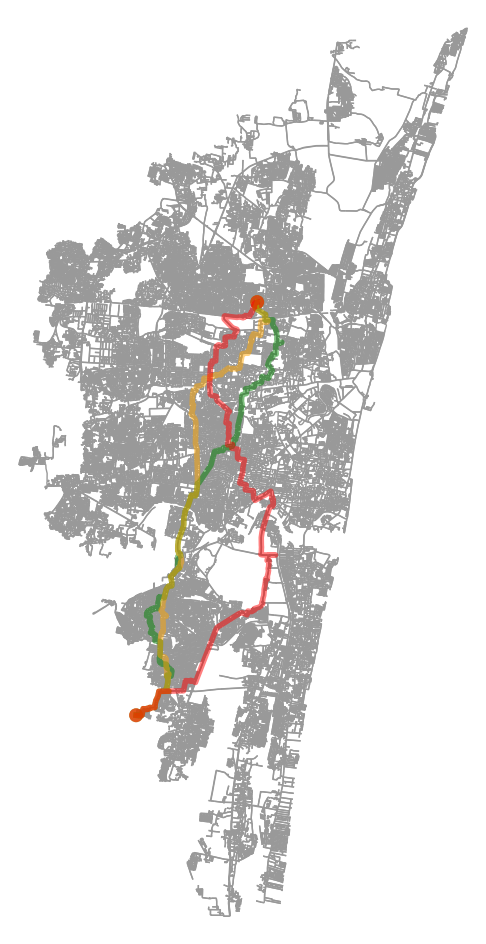

In [27]:

fig, ax = ox.plot_graph_routes(
    G,
    [route_normal, route_medium, route_heavy],
    route_colors=["green", "orange", "red"],
    route_linewidth=3,
    node_size=0,
    bgcolor="white",
    figsize=(12, 12)
)
plt.show()


## 24. Summarize Results
Create a table comparing route size and estimated travel time.

In [28]:

results = pd.DataFrame({
    "Traffic Condition": ["Normal", "Medium", "Heavy"],
    "Route Nodes": [
        len(route_normal),
        len(route_medium),
        len(route_heavy)
    ],
    "Estimated Time (minutes)": [
        round(route_time(route_normal, "time_normal") / 60, 2),
        round(route_time(route_medium, "time_medium") / 60, 2),
        round(route_time(route_heavy, "time_heavy") / 60, 2)
    ]
})

display(results)


,Traffic Condition,Route Nodes,Estimated Time (minutes)
0,Normal,450,21.38
1,Medium,381,18.81
2,Heavy,376,32.23


## 25. Save Results
Export the comparison table to CSV.

In [29]:

results.to_csv("chennai_astar_results.csv", index=False)

print("Results saved successfully!")



Results saved successfully!


In [30]:

results.to_csv("chennai_astar_results.csv", index=False)
print("CSV saved successfully!")


CSV saved successfully!


## 26. Save Normal-Traffic Route Map
Plot and save the normal-traffic route.

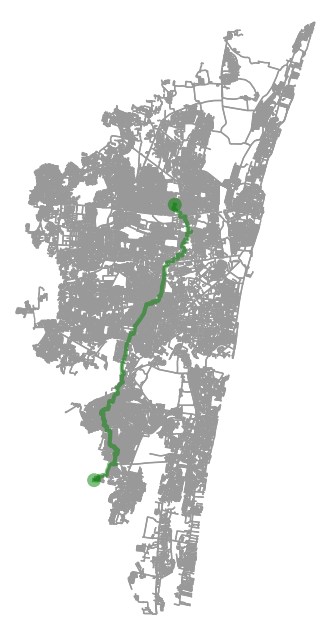

In [31]:

fig, ax = ox.plot_graph_route(
    G,
    route_normal,
    route_color="green",
    route_linewidth=3,
    node_size=0,
    bgcolor="white",
    show=False,
    close=False
)

fig.savefig("chennai_normal_route.png", dpi=300, bbox_inches="tight")
plt.show()


## 27. Save Medium-Traffic Route Map
Plot and save the medium-traffic route.

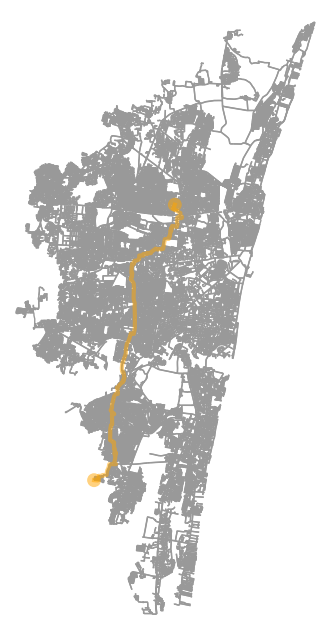

Medium route map saved!


In [32]:
fig, ax = ox.plot_graph_route(
    G,
    route_medium,
    route_color="orange",
    route_linewidth=3,
    node_size=0,
    bgcolor="white",
    show=False,
    close=False
)

fig.savefig("chennai_medium_route.png", dpi=300, bbox_inches="tight")
plt.show()

print("Medium route map saved!")

## 28. Save Heavy-Traffic Route Map
Plot and save the heavy-traffic route.

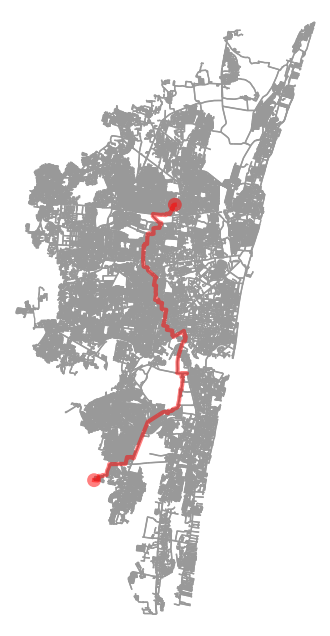

Heavy route map saved!


In [33]:
# we r saving heavy route map
fig, ax = ox.plot_graph_route(
    G,
    route_heavy,
    route_color="red",
    route_linewidth=3,
    node_size=0,
    bgcolor="white",
    show=False,
    close=False
)

fig.savefig("chennai_heavy_route.png", dpi=300, bbox_inches="tight")
plt.show()

print("Heavy route map saved!")

## 29. Review Best Estimated Route
Display the results and the lowest estimated time.

In [34]:
print("CHENNAI SMART TRAFFIC MANAGEMENT")
print(f"Route: {source_name} -> {destination_name}")
print("=" * 45)

display(results)

print("\nBest estimated travel time:")
best = results.loc[results["Estimated Time (minutes)"].idxmin()]
print(best)

CHENNAI SMART TRAFFIC MANAGEMENT
Route: Perambur - Vyasarpadi -> Tambaram Bypass


,Traffic Condition,Route Nodes,Estimated Time (minutes)
0,Normal,450,21.38
1,Medium,381,18.81
2,Heavy,376,32.23



Best estimated travel time:
Traffic Condition           Medium
Route Nodes                    381
Estimated Time (minutes)     18.81
Name: 1, dtype: object


## 30. Project Conclusion
Summarize the project steps and reported travel-time estimates.

In [35]:
print("PROJECT CONCLUSION")
print("-" * 40)
print(f"Journey: {source_name} to {destination_name}")
print("1. Chennai road network was loaded using OSMnx.")
print("2. A* algorithm was used to find routes.")
print("3. Three traffic conditions were compared.")

print(f"4. Normal traffic time: {route_time(route_normal, 'time_normal') / 60:.2f} minutes")
print(f"5. Medium traffic time: {route_time(route_medium, 'time_medium') / 60:.2f} minutes")
print(f"6. Heavy traffic time: {route_time(route_heavy, 'time_heavy') / 60:.2f} minutes")

print("\nConclusion:")
print("Estimated travel time increases significantly under heavy traffic.")
print("The A* algorithm effectively recalculates optimal routes under varying conditions.")

PROJECT CONCLUSION
----------------------------------------
Journey: Perambur - Vyasarpadi to Tambaram Bypass
1. Chennai road network was loaded using OSMnx.
2. A* algorithm was used to find routes.
3. Three traffic conditions were compared.
4. Normal traffic time: 21.38 minutes
5. Medium traffic time: 18.81 minutes
6. Heavy traffic time: 32.23 minutes

Conclusion:
Estimated travel time increases significantly under heavy traffic.
The A* algorithm effectively recalculates optimal routes under varying conditions.


In [36]:
import networkx as nx
import osmnx as ox

# 1. Recalculate A* Paths for the updated locations
print(f"Calculating optimal routes from {source_name} to {destination_name}...")
route_normal = nx.astar_path(G, start_node, end_node, heuristic=heuristic, weight='time_normal')
route_medium = nx.astar_path(G, start_node, end_node, heuristic=heuristic, weight='time_medium')
route_heavy = nx.astar_path(G, start_node, end_node, heuristic=heuristic, weight='time_heavy')

print("Routes calculated successfully!")

Calculating optimal routes from Perambur - Vyasarpadi to Tambaram Bypass...
Routes calculated successfully!


In [37]:
import pandas as pd

# 2. Build and display the comparison summary table
results_df = pd.DataFrame({
    "Traffic Condition": ["Normal", "Medium", "Heavy"],
    "Route Nodes": [len(route_normal), len(route_medium), len(route_heavy)],
    "Estimated Time (minutes)": [
        round(route_time(route_normal, "time_normal") / 60, 2),
        round(route_time(route_medium, "time_medium") / 60, 2),
        round(route_time(route_heavy, "time_heavy") / 60, 2)
    ]
})

print(f"Summary Results for: {source_name} -> {destination_name}")
display(results_df)

Summary Results for: Perambur - Vyasarpadi -> Tambaram Bypass


,Traffic Condition,Route Nodes,Estimated Time (minutes)
0,Normal,450,21.38
1,Medium,381,18.81
2,Heavy,376,32.23


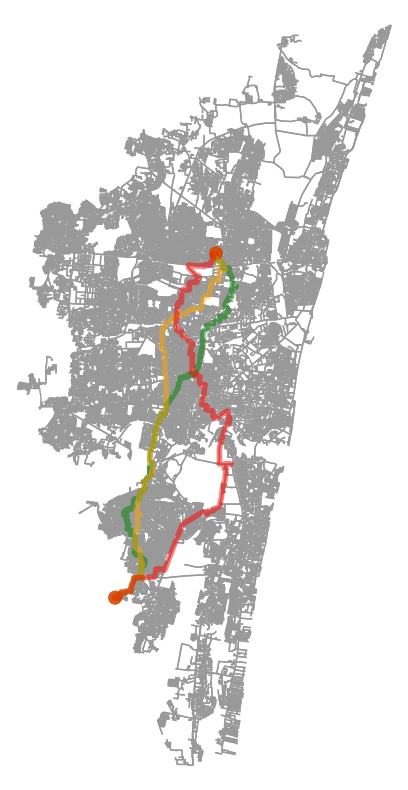

In [38]:
import matplotlib.pyplot as plt

# 3. Plot and display all three routes comparison map
fig, ax = ox.plot_graph_routes(
    G,
    [route_normal, route_medium, route_heavy],
    route_colors=["green", "orange", "red"],
    route_linewidth=3,
    node_size=0,
    bgcolor="white",
    figsize=(10, 10)
)
plt.show()

In [39]:
import pandas as pd

# Find the route with the lowest travel time
best_route_idx = results_df["Estimated Time (minutes)"].idxmin()
best_row = results_df.iloc[best_route_idx]

print("=== RECOMMENDED OPTIMAL ROUTE ===")
print(f"Source: {source_name}")
print(f"Destination: {destination_name}")
print(f"Selected Scenario: {best_row['Traffic Condition']} Route")
print(f"Optimal Time Cost: {best_row['Estimated Time (minutes)']} minutes")
print(f"Path Node Complexity: {best_row['Route Nodes']} nodes")
print("=================================")


=== RECOMMENDED OPTIMAL ROUTE ===
Source: Perambur - Vyasarpadi
Destination: Tambaram Bypass
Selected Scenario: Medium Route
Optimal Time Cost: 18.81 minutes
Path Node Complexity: 381 nodes


In [40]:
# Extract road names along the Medium Traffic Route
path_details = []
for u, v in zip(route_medium[:-1], route_medium[1:]):
    edge_data = G.get_edge_data(u, v)
    # Get the road name if available, otherwise default to 'Unnamed Road'
    road_name = next(iter(edge_data.values())).get('name', 'Unnamed Road')
    if isinstance(road_name, list):
        road_name = ", ".join(road_name)
    path_details.append(road_name)

# Deduplicate consecutive street names for a clean itinerary representation
clean_itinerary = []
for road in path_details:
    if not clean_itinerary or clean_itinerary[-1] != road:
        clean_itinerary.append(road)

print("=== STREET-BY-STREET TRAVEL PATH (MEDIUM ROUTE) ===")
for idx, road in enumerate(clean_itinerary, 1):
    print(f"{idx}. {road}")

print("\n=== ALL 381 NODE IDS IN SEQUENCE ===")
print(route_medium)

=== STREET-BY-STREET TRAVEL PATH (MEDIUM ROUTE) ===
1. sabapathy Street
2. Unnamed Road
3. Paper Mills Road
4. Tank Bund Road
5. Unnamed Road
6. Pilkington Road
7. Unnamed Road
8. Perambur High Road
9. Pilkington Road
10. Vasantha Garden Street
11. Mudurpillai Street
12. Unnamed Road
13. Konnur High Road
14. Unnamed Road
15. Konnur High Road
16. Somasundaram 4th street
17. Unnamed Road
18. Ayanavaram Road
19. Raji Street
20. Ainavaram Jn
21. Palli Arasan street
22. Palli Arasan street, Palliarasan street
23. Unnamed Road
24. 12th Street
25. Unnamed Road
26. Anna Nagar 2nd Avenue
27. Unnamed Road
28. Anna Arch Road
29. 4th Avenue (Santhi Colony Road)
30. 7th Main Road
31. Unnamed Road
32. Maduvankarai Bridge
33. Unnamed Road
34. EVR Periyar Salai
35. Unnamed Road
36. Jawaharlal Nehru Road (100 Feet Road)
37. Jawaharlal Nehru Road
38. Jawaharlal Nehru Road (100 Feet Road)
39. Jawaharlal Nehru Road (100 Feet Road), Inner Ring Road
40. Inner Ring Road
41. Unnamed Road
42. Inner Ring Road
4